# Регрессионный анализ

**Цель работы:**

Изучение алгоритмов регрессии на практике (простая, полиномиальная, сравнение методов и т.д.).

### Индивидуальный вариант

Вариант №1 (лист var1)

Набор данных: датасет regression.xlsx содержит информацию о признаках объектов $x1, x2, y$.  

### 1. Простая линейная регрессия

#### 1.1 Загрузка данных и их оценка 

Загрузка датасета с помощью библиотеки pandas. Исходные табличные данные преобразуются в датафрейм.

In [1]:
import pandas as pd

df = pd.read_excel('regression.xlsx', sheet_name='var1')
df.head()

,x1,x2,y
0,1.929428,1.511727,5.734255
1,-0.330281,-0.898878,-0.623706
2,0.688773,0.908247,1.028884
3,-0.008892,-0.518823,-0.894802
4,-1.698716,0.610347,2.822400


In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   x1      1000 non-null   float64
 1   x2      1000 non-null   float64
 2   y       1000 non-null   float64
dtypes: float64(3)
memory usage: 23.6 KB


Датасет содержит 1000 объектов, каждый из которых имеет 3 признака (без пропусков). Все столбцы содержат вещественные числа.  
Выведем числовые характеристики признаков:

In [3]:
df.describe()

,x1,x2,y
count,1000.000000,1000.000000,1000.000000
mean,-0.000004,0.000028,1.328769
std,1.155279,1.155227,1.615985
min,-1.999458,-1.998031,-2.722868
25%,-0.999670,-0.999294,0.072635
50%,0.000488,-0.000001,1.256896
75%,0.998817,0.999619,2.418257
max,1.999308,1.997041,5.734255


Можно сказать, что масштабы трех переменных сопоставимы (все порядка единиц), сильной необходимости в стандартизации на этом этапе нет. Наибольший размах имеет признак y. Средние переменных x1 и x2 ≈ 0. 

#### 1.2 Подсчёт коэффициентов корреляции 

Корреляция – это статистическая мера **линейной** зависимости между двумя переменными. Наличие корреляции не доказывает причинно-следственную связь, а указывает на статистическую зависимость.
Корреляция может быть измерена с помощью коэффициента корреляции, такого как коэффициент Пирсона. Корреляция Пирсона измеряет степень и направление линейной взаимосвязи между двумя переменными. Коэффициент Пирсона (обозначается как r) показывает, насколько близко точки данных на диаграмме рассеяния ложатся на прямую линию.  
По его значению можно судить о силе линейной связи: 0.9 — сильная линейная связь, 0.1 — слабая. Чувствителен к выбросам.
Метод corr() по умолчанию считает именно коэффициент Пирсона:

In [4]:
df.corr(numeric_only=True)

,x1,x2,y
x1,1.000000,0.029707,0.031201
x2,0.029707,1.000000,0.577203
y,0.031201,0.577203,1.000000


По корреляционной матрице можно сделать промежуточный вывод об отсутствии сильной линейной связи между признаками объектов $x1$ и $x2$, а также $x1$ и $y$. Значение $r(x2, y)≈0,6$ может говорить о наличии умеренной положительной связи. Для визуального анализа построим матрицу диаграмм рассеяния для нескольких признаков набора данных, которая отражает попарные взаимосвязи величин: 

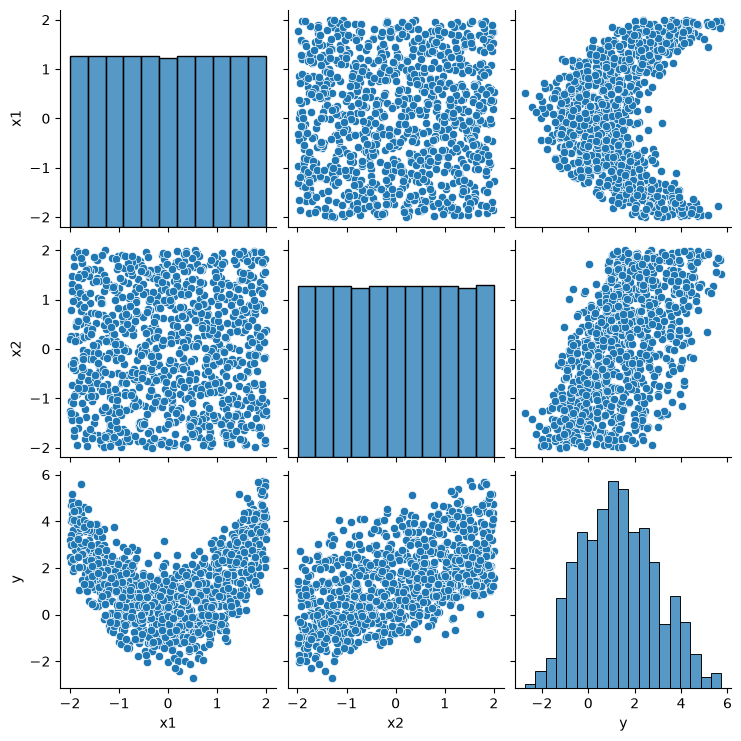

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.pairplot(df[['x1', 'x2', 'y']])

По полученным диаграммам рассеивания можно сделать вывод:
- Зависимость $x1-y$ явно описывается нелинейной функцией (скопление точек напоминает параболическую функцию). В дальнейшем для $x1$ стоит использовать полиномиальную регрессию;
- Точки на диаграмме $x1-x2$ визуально равномерно распределены по всей декартовой плоскости, что говорит об однозначном отсутствии зависимости между переменными;
- Точки $x2-y$ образуют широкую полосу, чётко прослеживается возрастающее направление: бОльшим значениям фичи $x2$ соответствуют бОльшие значения y (что подтверждает полученный выше положительный r). Для $x2$ линейная модель может быть подходящей.

По диагонали стоят гистограммы, которые показывают распределение каждого признака по отдельности:
- Признаки $x_1$ и $x_2$ выглядят примерно равномерно распределёнными на отрезке примерно $[-2, 2]$ (плоские гистограммы, почти одинаковая плотность);
- $y$ имеет сложное распределение с двумя пиками (бимодальное)

Обучить модель простой (парной) линейной регрессии, используя для обучения значения и , а затем и
y.
х1 y х2
Не забудьте разделить выборку. 
    

#### 1.3 Обучение модели парной линейной регрессии

Цель задачи регрессии - построить модель, которая может предсказать численные значения для
новых наблюдений, основываясь на известных данных.
Для этого модель анализирует связь между независимыми переменными (предикторами) и
зависимой переменной (целевой переменной).  
Наиболее распространенной формой регрессии является линейная регрессия, где предполагается, что
зависимая переменная линейно зависит от независимых переменных.
При этом если независимая переменная одна – это простая линейная регрессия, а если две и более, то – это
множественная линейная регрессия.


Целевой признак находится в столбце `y`. В данном примере предиктором является признак, находящийся в столбце `x1`.  
Функция `train_test_split` принимает эти столбцы в качестве параметров и делит данные на 4 выборки: `X_train, X_test, y_train, y_test`. Можно задать размер
валидационной выборки параметром `test_size`, который выражается в долях – от 0 до 1. Некоторые объекты `scikit-learn` по своей природе случайны, и их случайность
контролируется с помощью `random_state` параметра. Он позволяет получать повторяемые результаты при каждом запуске модели.

In [6]:
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
import numpy as np


X_train1, X_test1, y_train1, y_test1 = train_test_split(
 df['x1'],
 df['y'],
 test_size=0.25,
 random_state=15)

model_x1 = LinearRegression()
model_x1.fit(np.array(X_train1).reshape(-1, 1), y_train1)
predictions_valid1 = model_x1.predict(np.array(X_test1).reshape(-1, 1))
df_match1 = pd.DataFrame({'Actual': y_test1, 'Predicted (x1)':
predictions_valid1})
display(df_match1)

,Actual,Predicted (x1)
825,-0.229188,1.266898
374,-0.181388,1.231412
488,1.152927,1.195584
608,0.953596,1.224287
42,4.793899,1.413391
...,...,...
827,0.385307,1.355918
690,1.091206,1.274239
907,-1.424944,1.299259
299,-2.004640,1.317749


При визуальном анализе фрагмента полученной таблицы наблюдается существенное расхождение между предсказанными и реальными значениями целевого признака (встречаются пары `(-2.004640; 1.317749)`, тогда как `std(y) ≈ 1.62`. Данный результат вызван нелинейностью связи признаков `x1` и `y`, которая прослеживается на диаграмме рассеивания и согласуется с `r ≈ 0.03`. Построим аналогичную таблицу для связи признаков `x2` и `y`:

In [7]:
X_train2, X_test2, y_train2, y_test2 = train_test_split(
 df['x2'],
 df['y'],
 test_size=0.25,
 random_state=15)

model_x2 = LinearRegression()
model_x2.fit(np.array(X_train2).reshape(-1, 1), y_train2)
predictions_valid2 = model_x2.predict(np.array(X_test2).reshape(-1, 1))
df_match2 = pd.DataFrame({'Actual': y_test2, 'Predicted (x2)':
predictions_valid2})
display(df_match2)

,Actual,Predicted (x2)
825,-0.229188,0.029760
374,-0.181388,0.325638
488,1.152927,-0.050535
608,0.953596,0.311600
42,4.793899,2.742728
...,...,...
827,0.385307,1.168630
690,1.091206,2.533288
907,-1.424944,0.466791
299,-2.004640,0.304009


Модель по `x_2`показывает меньшие отклонения, что соответствует умеренной положительной корреляции.

#### 1.4 Метрики качества линейной регрессии.
Оценку качества работы моделей проводят с использованием метрик качества регрессии ( MSE , MAE , RMSE , R2 ).


In [8]:
from sklearn import metrics

print('____________________x1___________________')
print('Mean Absolute Error:', metrics.mean_absolute_error(y_test1, predictions_valid1))
print('Mean Squared Error:', metrics.mean_squared_error(y_test1, predictions_valid1))
print('Root Mean Squared Error:', np.sqrt(metrics.mean_squared_error(y_test1, predictions_valid1)))
print('R2 metric:', metrics.r2_score(y_test1, predictions_valid1))

print('____________________x2___________________')
print('Mean Absolute Error:', metrics.mean_absolute_error(y_test2, predictions_valid2))
print('Mean Squared Error:', metrics.mean_squared_error(y_test2, predictions_valid2))
print('Root Mean Squared Error:', np.sqrt(metrics.mean_squared_error(y_test2, predictions_valid2)))
print('R2 metric:', metrics.r2_score(y_test2, predictions_valid2))

____________________x1___________________
Mean Absolute Error: 1.3659800153322441
Mean Squared Error: 2.805167704050783
Root Mean Squared Error: 1.6748634881836737
R2 metric: -0.006663004440029097
____________________x2___________________
Mean Absolute Error: 1.1064481175550946
Mean Squared Error: 1.7814133155766667
Root Mean Squared Error: 1.3346959637223252
R2 metric: 0.3607216859732474


Интерпретация:
- MAE равна средней абсолютной ошибке, оценить её можно только зная масштаб целевого признака;
- MSE - среднеквадратическая ошибка. В отличие от MAE более подвержена выбросам. RMSE возвращает размерность ошибки к шкале целевого признака.
- Коэффициент детерминации R2 – метрика, которую нужно максимизировать, определяет долю изменений,
обусловленных влиянием признаков на целевую переменную.

По значениями MAE, MSE, RMSE нельзя однозначно говорить об ошибке, важно сопоставлять полученные метрики с масштабом целевой переменной. Известно, что среднее `y ≈  1.3`, а стандартное кв. отклонение `std ≈ 1.6`.  
Модель по `x_1`: $R^2 < 0$, MAE и RMSE сравнимы со стандартным отклонением `y`. Линейная регрессия не улавливает зависимость и работает хуже предсказания средним.  
Модель по `x_2`: $R^2$ положительный, но невысокий (`≈ 0.3`); ошибки меньше, чем у модели по `x_1`, однако всё ещё значительны относительно масштаба `y`. Линейная связь есть, но объясняет лишь умеренную долю дисперсии. 

#### 1.5 Визуализация регрессии
Чтобы построить линию регрессии необходимо получить коэффициенты с помощью `coef_` и `intercept_`
(свободный коэффициент), по которым строится график. Это коэффициенты в формуле `y = ax + b` – график прямой линии.
Таким образом, можно построить распределение точек исходного датасета df и линию регрессии по формуле.  
Построим диаграммы рассеивания исходных наблюдений с наложенными теоретическими линиями регрессии:

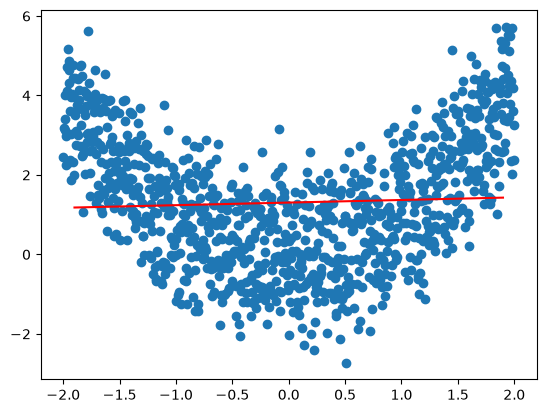

In [9]:
# Получение коэф регрессии
a1 = model_x1.coef_
b1 = model_x1.intercept_

plt.scatter(df['x1'], df['y']) # зависимость целевого столбца от конкретного столбца х1 (точечный график)
plt.plot([-1.9, 1.9], [a1*(-1.9) + b1, a1*(1.9) + b1], "r")
# df.columns

Линия регрессии не учитывает U-образную форму облака точек, никак не сопоставляется с его непостоянным характером. Отсюда и низкие метрики точности предсказаний `model_x1`, линейная модель непригодна для этой пары признаков.

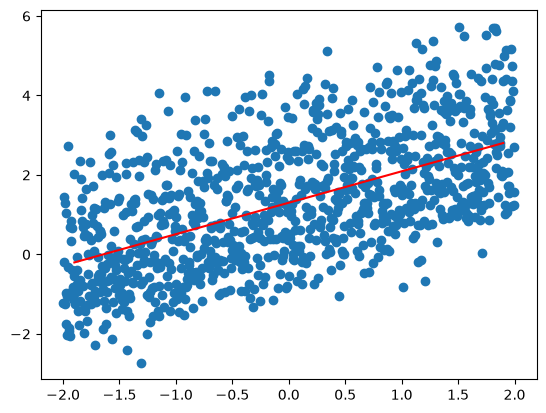

In [10]:
a2 = model_x2.coef_
b2 = model_x2.intercept_

plt.scatter(df['x2'], df['y']) # зависимость целевого столбца от конкретного столбца х1 (точечный график)
plt.plot([-1.9, 1.9], [a2*(-1.9) + b2, a2*(1.9) + b2], "r")
# df.columns

Здесь же линия регрессии достаточно хорошо описывает траекторию диаграммы рассеивания, но из-за значительного разброса точек вокруг неё метрики качества предсказательной способности модели `model_x2` показывают умеренные значения.

#### 1.6 Диагностический анализ остатков регрессии
Остатки в контексте регрессионных моделей представляют собой разницу между наблюдаемым значением целевой переменной и прогнозируемым значением - ошибка прогноза. График, представляющий разницу предсказанного и истинного значения в каждой точке, называется **графиком остатков (Residuals Plot)**. Он показывает разницу между остатками на вертикальной оси и зависимой переменной на горизонтальной оси, что позволяет обнаружить области внутри цели, которые могут быть подвержены
большей или меньшей ошибке.  
Если точки хаотично и симметрично рассеяны полосой постоянной ширины вдоль горизонтальной оси `e = 0`, можно говорить о состоятельности гипотез классической
линейной регрессии. 

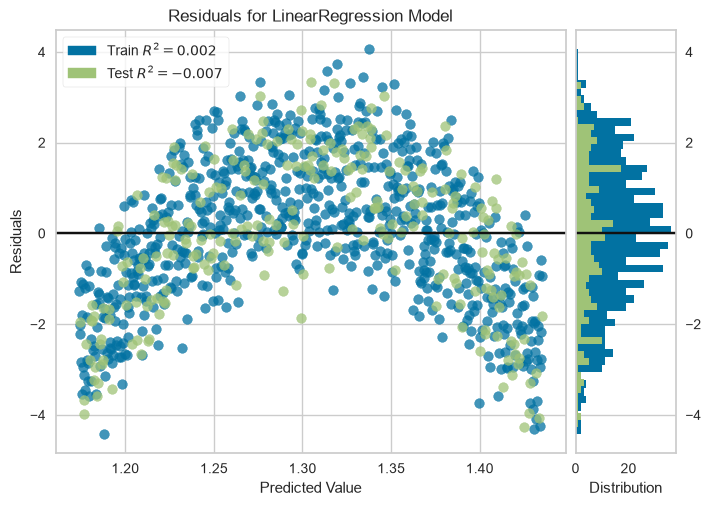

<Axes: title={'center': 'Residuals for LinearRegression Model'}, xlabel='Predicted Value', ylabel='Residuals'>

In [12]:
 from yellowbrick.regressor import ResidualsPlot

visualizer1 = ResidualsPlot(LinearRegression(), force_model=True)
visualizer1.fit(np.array(X_train1).reshape(-1, 1), y_train1)
visualizer1.score(np.array(X_test1).reshape(-1, 1), y_test1)
visualizer1.show()

Наибольшие отклонения наблюдаются по краям и в центре промежутка значений `y`. Такая форма облака остатков сигнализирует о том, что линейная модель упускает нелинейную зависимость. Метрики $R^2$ для обеих выборок примерно одинаковы и ≈ 0

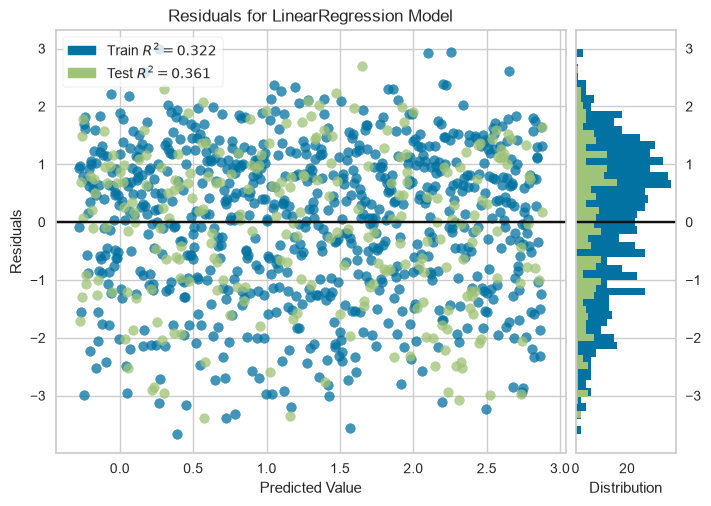

<Axes: title={'center': 'Residuals for LinearRegression Model'}, xlabel='Predicted Value', ylabel='Residuals'>

In [13]:
visualizer2 = ResidualsPlot(LinearRegression(), force_model=True)
visualizer2.fit(np.array(X_train2).reshape(-1, 1), y_train2)
visualizer2.score(np.array(X_test2).reshape(-1, 1), y_test2)
visualizer2.show()

На отрицательной области значений точек значительно меньше, бОльшую плотность имеет верхняя часть полосы. При этом вдоль горизонтальной оси `e = 0` точки разбросаны равномерно, значит для данных может подходить модель линейной регрессии.